# STW7089CEM — Modelling Cloud Server Power Consumption
**Manav Paudel | Student ID: 260543**





## Task 1 — Preliminary Data Analysis
### 1.0 Libraries and setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rng = np.random.default_rng(42)
plt.style.use('seaborn-v0_8-whitegrid')

### 1.1 Load and align the input, target, and time files

In [2]:
def load_dataset(filename):
    for option in (filename, filename.lower(), filename.upper()):
        if os.path.exists(option):
            return pd.read_csv(option)
    raise FileNotFoundError(f'Could not locate {filename}. Place the CSV files next to this notebook.')

X_df = load_dataset('x.csv')
y_df = load_dataset('y.csv')
time_df = load_dataset('time.csv')
assert X_df.shape[1] == 4, 'Expected exactly four telemetry input columns'
assert y_df.shape[1] == 1 and time_df.shape[1] == 1, 'Unexpected target/time CSV columns'
assert len(X_df) == len(y_df) == len(time_df), 'Unequal sample counts; cannot align telemetry with power'

X_df.columns = ['x1', 'x2', 'x3', 'x4']
y_df.columns = ['y']
time_df.columns = ['Time']
data_df = pd.concat([time_df, X_df, y_df], axis=1)
for col in data_df:
    data_df[col] = pd.to_numeric(data_df[col], errors='raise')
assert not data_df.isna().any().any(), 'The dataset contains missing values; inspect before modeling'
assert np.isfinite(data_df.to_numpy(dtype=float)).all(), 'Nonfinite values detected; inspect before modeling'
assert data_df.Time.is_monotonic_increasing, 'Time values are not sorted'
assert data_df.Time.is_unique, 'Duplicate time stamps'

print(f'Master Dataset Shape: {len(data_df)} rows, {data_df.shape[1]} columns')
print('Telemetry variables are labelled x1–x4; the CSV files do not independently establish physical units.')
print(f'Time step (median): {data_df.Time.diff().median():.4f} s')
display(data_df.head())

Master Dataset Shape: 10000 rows, 6 columns
Telemetry variables are labelled x1–x4; the CSV files do not independently establish physical units.
Time step (median): 0.1000 s


,Time,x1,x2,x3,x4,y
0,0.0,3.621781,4.615486,3.794295,1.172840,351.653626
1,0.1,7.655000,4.330385,5.878988,0.483354,1616.590690
2,0.2,6.123958,3.233077,6.959421,3.276880,2295.294758
3,0.3,5.190609,6.250867,3.159626,0.843853,377.639620
4,0.4,2.092130,5.336369,7.568462,1.828161,2771.901091


### 1.2 Data quality and descriptive statistics

In [3]:
missing_summary = data_df.isna().sum().to_frame(name='Missing Values')
print('--- Data Completeness Check ---')
print(missing_summary)
print('--- Summary Statistics ---')
display(data_df.describe().T)
print('Duplicated rows:', int(data_df.duplicated().sum()))
print('Nonpositive or nonfinite power values:', int((~np.isfinite(data_df.y) | (data_df.y <= 0)).sum()))

--- Data Completeness Check ---
      Missing Values
Time               0
x1                 0
x2                 0
x3                 0
x4                 0
y                  0
--- Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
Time,10000.0,499.950000,288.689568,0.000000,249.975000,499.950000,749.925000,999.900000
x1,10000.0,4.459117,2.013411,1.000081,2.724302,4.447700,6.180044,7.998024
x2,10000.0,5.531709,2.025062,2.001104,3.777621,5.541277,7.295355,8.999474
x3,10000.0,5.004903,1.483851,-0.784563,3.986363,5.008148,6.011645,11.718626
x4,10000.0,2.999603,2.999624,0.000017,0.865088,2.081428,4.142377,27.360529
y,10000.0,1084.104118,883.509897,121.714500,507.113273,828.349137,1375.905259,15241.251036


Duplicated rows: 0
Nonpositive or nonfinite power values: 0


### 1.3 Time-series plots — each signal separately

#### 1.3.1 Time series of `x1`

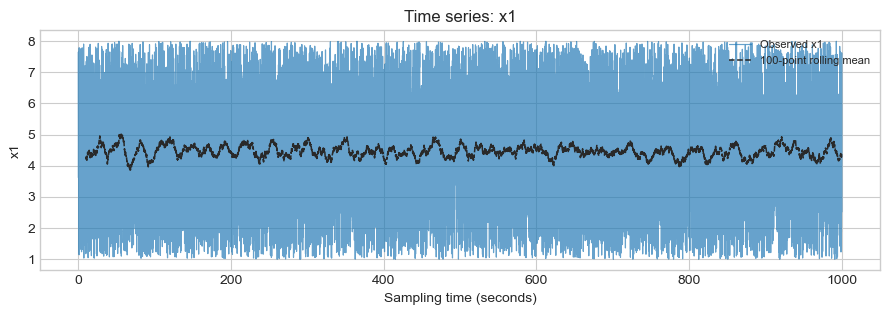

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.25))
ax.plot(data_df['Time'], data_df['x1'], color='#1f77b4', alpha=0.68, linewidth=0.85, label='Observed x1')
ax.plot(data_df['Time'], data_df['x1'].rolling(100).mean(), color='#292929', linestyle='--', linewidth=1.1, label='100-point rolling mean')
ax.set(title='Time series: x1', xlabel='Sampling time (seconds)', ylabel='x1')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

#### 1.3.2 Time series of `x2`

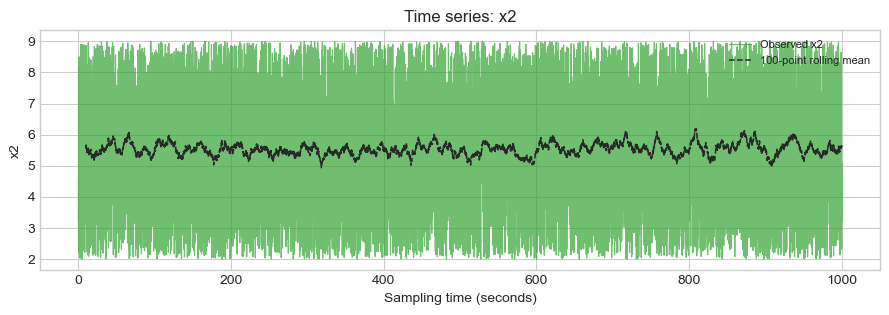

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.25))
ax.plot(data_df['Time'], data_df['x2'], color='#2ca02c', alpha=0.68, linewidth=0.85, label='Observed x2')
ax.plot(data_df['Time'], data_df['x2'].rolling(100).mean(), color='#292929', linestyle='--', linewidth=1.1, label='100-point rolling mean')
ax.set(title='Time series: x2', xlabel='Sampling time (seconds)', ylabel='x2')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

#### 1.3.3 Time series of `x3`

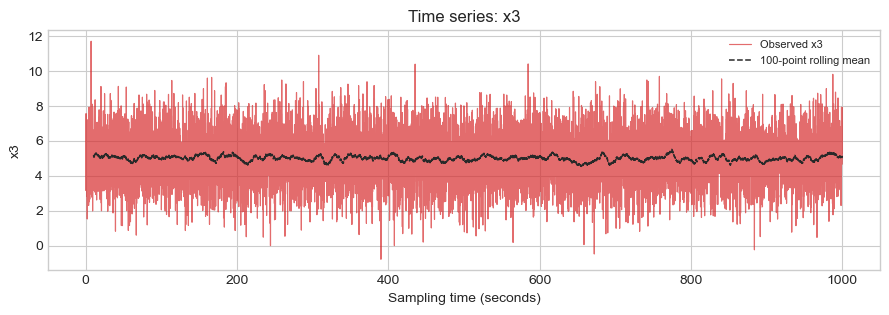

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.25))
ax.plot(data_df['Time'], data_df['x3'], color='#d62728', alpha=0.68, linewidth=0.85, label='Observed x3')
ax.plot(data_df['Time'], data_df['x3'].rolling(100).mean(), color='#292929', linestyle='--', linewidth=1.1, label='100-point rolling mean')
ax.set(title='Time series: x3', xlabel='Sampling time (seconds)', ylabel='x3')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

#### 1.3.4 Time series of `x4`

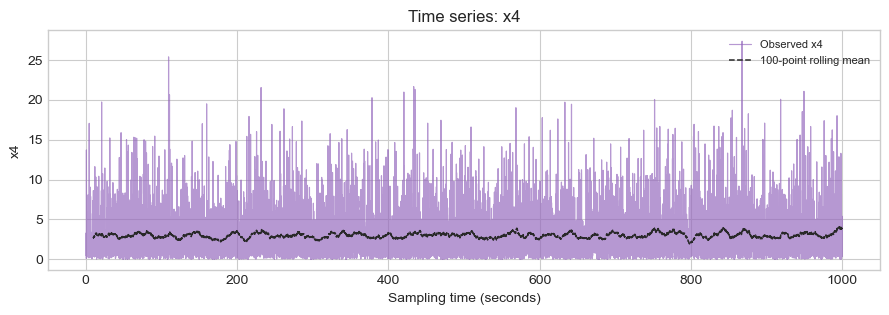

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.25))
ax.plot(data_df['Time'], data_df['x4'], color='#9467bd', alpha=0.68, linewidth=0.85, label='Observed x4')
ax.plot(data_df['Time'], data_df['x4'].rolling(100).mean(), color='#292929', linestyle='--', linewidth=1.1, label='100-point rolling mean')
ax.set(title='Time series: x4', xlabel='Sampling time (seconds)', ylabel='x4')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

#### 1.3.5 Time series of `y`

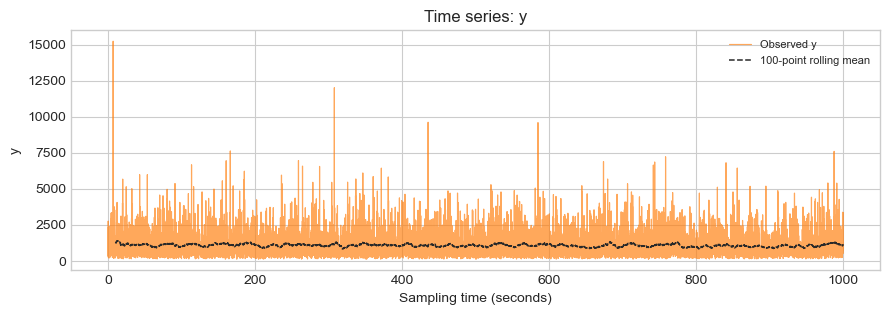

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.25))
ax.plot(data_df['Time'], data_df['y'], color='#ff7f0e', alpha=0.68, linewidth=0.85, label='Observed y')
ax.plot(data_df['Time'], data_df['y'].rolling(100).mean(), color='#292929', linestyle='--', linewidth=1.1, label='100-point rolling mean')
ax.set(title='Time series: y', xlabel='Sampling time (seconds)', ylabel='y')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

### 1.4 Marginal distributions — one histogram for each signal

#### 1.4.1 Distribution of `x1`

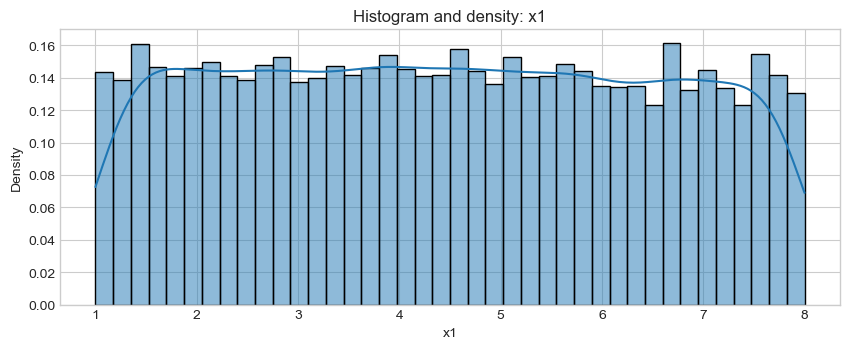

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.histplot(data_df['x1'], kde=True, bins=40, stat='density', color='#1f77b4', ax=ax)
ax.set(title='Histogram and density: x1', xlabel='x1', ylabel='Density')
plt.tight_layout()
plt.show()

#### 1.4.2 Distribution of `x2`

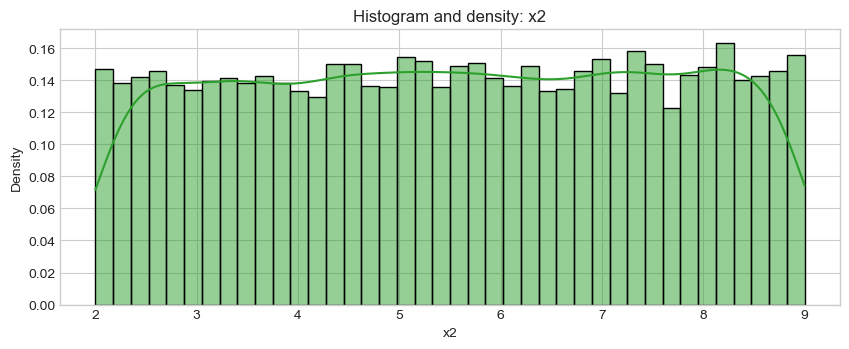

In [10]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.histplot(data_df['x2'], kde=True, bins=40, stat='density', color='#2ca02c', ax=ax)
ax.set(title='Histogram and density: x2', xlabel='x2', ylabel='Density')
plt.tight_layout()
plt.show()

#### 1.4.3 Distribution of `x3`

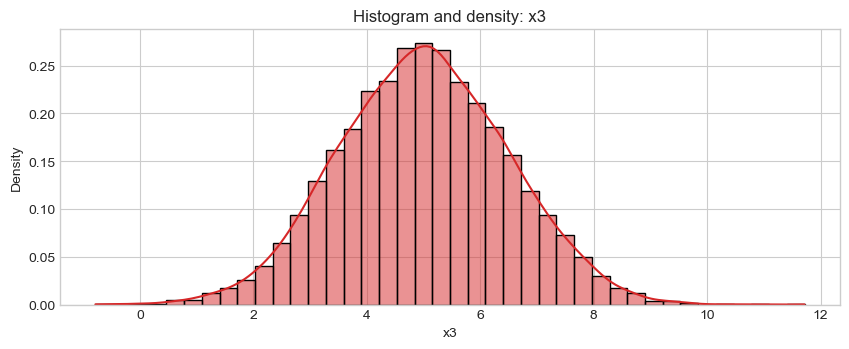

In [11]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.histplot(data_df['x3'], kde=True, bins=40, stat='density', color='#d62728', ax=ax)
ax.set(title='Histogram and density: x3', xlabel='x3', ylabel='Density')
plt.tight_layout()
plt.show()

#### 1.4.4 Distribution of `x4`

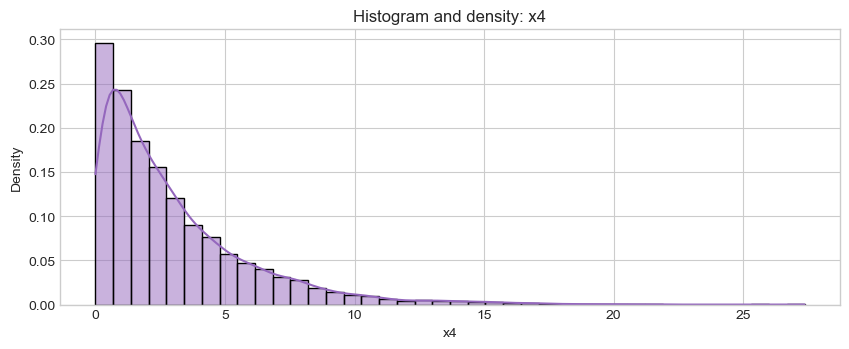

In [12]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.histplot(data_df['x4'], kde=True, bins=40, stat='density', color='#9467bd', ax=ax)
ax.set(title='Histogram and density: x4', xlabel='x4', ylabel='Density')
plt.tight_layout()
plt.show()

#### 1.4.5 Distribution of `y`

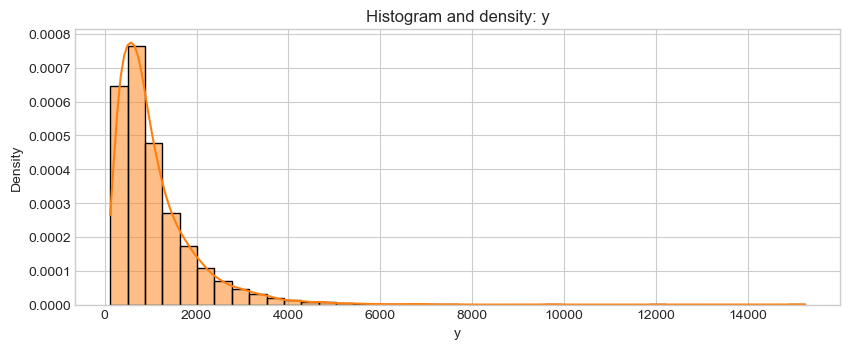

In [13]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.histplot(data_df['y'], kde=True, bins=40, stat='density', color='#ff7f0e', ax=ax)
ax.set(title='Histogram and density: y', xlabel='y', ylabel='Density')
plt.tight_layout()
plt.show()

### 1.5 Scatter plots — each input versus power

#### 1.5.1 Scatter plot of `x1` against `y`

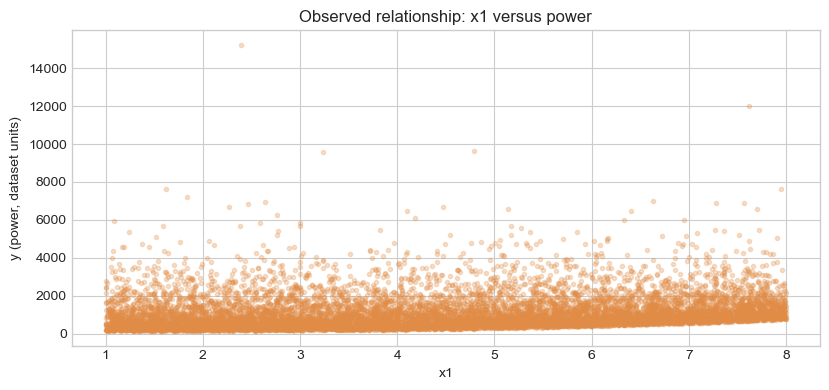

In [14]:
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.scatter(data_df['x1'], data_df['y'], s=9, alpha=0.28, color='#e18c46', rasterized=True)
ax.set(title='Observed relationship: x1 versus power', xlabel='x1', ylabel='y (power, dataset units)')
plt.tight_layout()
plt.show()

#### 1.5.2 Scatter plot of `x2` against `y`

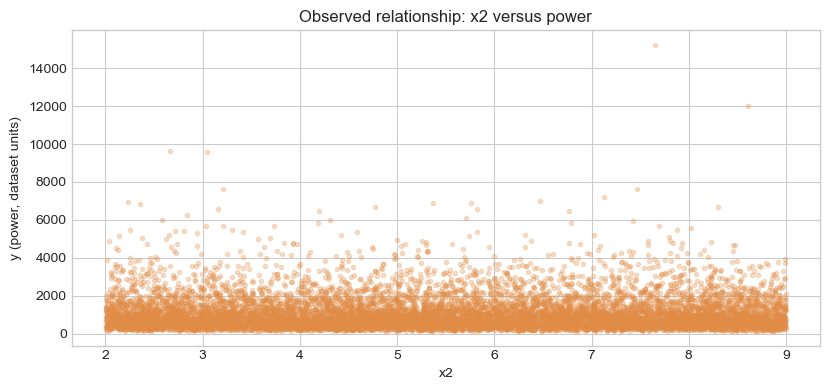

In [15]:
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.scatter(data_df['x2'], data_df['y'], s=9, alpha=0.28, color='#e18c46', rasterized=True)
ax.set(title='Observed relationship: x2 versus power', xlabel='x2', ylabel='y (power, dataset units)')
plt.tight_layout()
plt.show()

#### 1.5.3 Scatter plot of `x3` against `y`

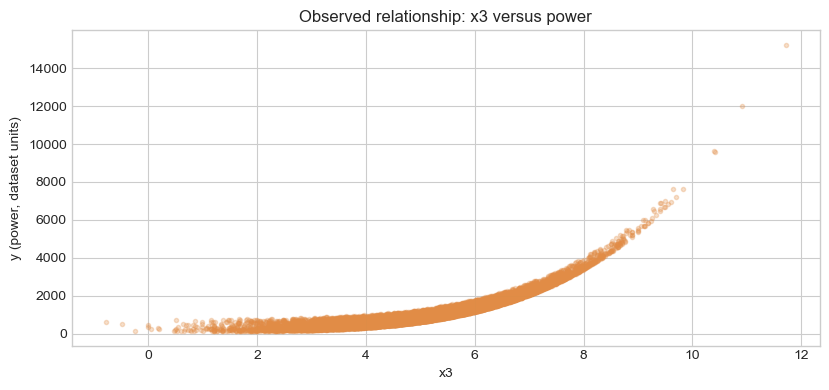

In [16]:
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.scatter(data_df['x3'], data_df['y'], s=9, alpha=0.28, color='#e18c46', rasterized=True)
ax.set(title='Observed relationship: x3 versus power', xlabel='x3', ylabel='y (power, dataset units)')
plt.tight_layout()
plt.show()

#### 1.5.4 Scatter plot of `x4` against `y`

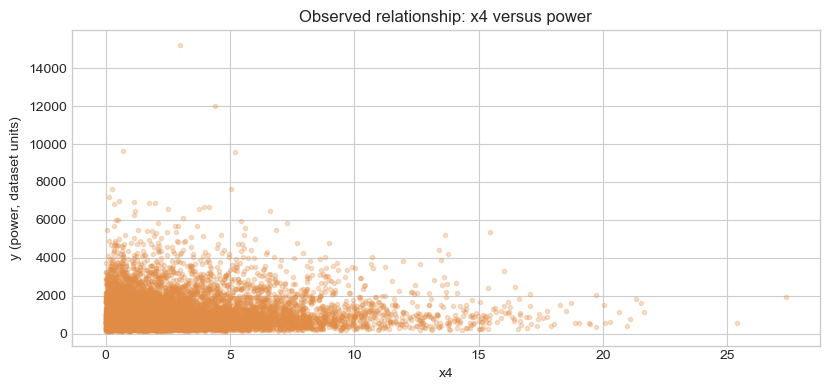

In [17]:
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.scatter(data_df['x4'], data_df['y'], s=9, alpha=0.28, color='#e18c46', rasterized=True)
ax.set(title='Observed relationship: x4 versus power', xlabel='x4', ylabel='y (power, dataset units)')
plt.tight_layout()
plt.show()

### 1.6 Pearson correlation heatmap

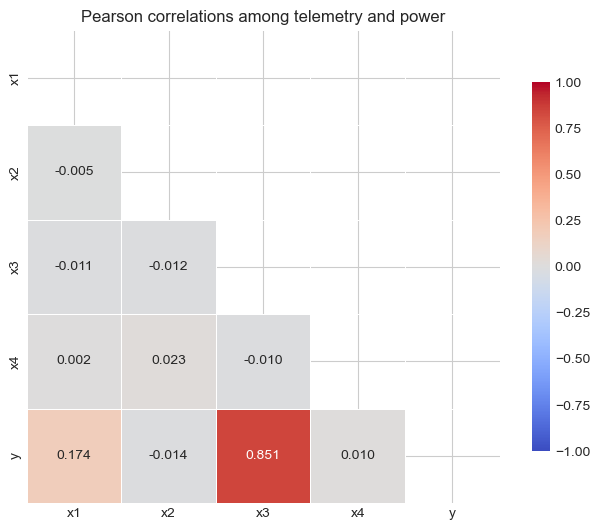

Correlations with power:


,Pearson r with power
x1,0.173824
x2,-0.013960
x3,0.851343
x4,0.010429


In [18]:
signals = ['x1','x2','x3','x4','y']
corr_matrix = data_df[signals].corr()
fig, ax = plt.subplots(figsize=(6.8,5.4))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,mask=mask,annot=True,cmap='coolwarm',vmin=-1,vmax=1,fmt='.3f',linewidths=0.7,square=True,cbar_kws={'shrink':0.78},ax=ax)
ax.set_title('Pearson correlations among telemetry and power')
plt.tight_layout();plt.show()
print('Correlations with power:')
display(corr_matrix[['y']].loc[['x1','x2','x3','x4']].rename(columns={'y':'Pearson r with power'}))

## Task 2 — Polynomial Regression and Model Selection
### 2.1 Prescribed candidate polynomial terms

In [19]:
candidate_models = {
    "Model 1": pd.DataFrame({
        'x4': data_df['x4'], 
        'x1_sq': data_df['x1']**2, 
        'x1_cube': data_df['x1']**3, 
        'x2_quad': data_df['x2']**4, 
        'x1_quad': data_df['x1']**4
    }),
    "Model 2": pd.DataFrame({
        'x4': data_df['x4'], 
        'x1_cube': data_df['x1']**3, 
        'x3_quad': data_df['x3']**4
    }),
    "Model 3": pd.DataFrame({
        'x3_cube': data_df['x3']**3, 
        'x3_quad': data_df['x3']**4
    }),
    "Model 4": pd.DataFrame({
        'x2': data_df['x2'], 
        'x1_cube': data_df['x1']**3, 
        'x3_quad': data_df['x3']**4
    }),
    "Model 5": pd.DataFrame({
        'x4': data_df['x4'], 
        'x1_sq': data_df['x1']**2, 
        'x1_cube': data_df['x1']**3, 
        'x3_quad': data_df['x3']**4
    })
}

# Verify the construction by printing the features of each model
print("=" * 70)
print("TASK 2: Candidate Models Constructed Successfully")
print("=" * 70)
for model_name, features in candidate_models.items():
    print(f"{model_name} has {len(features.columns)} polynomial slopes (plus an intercept):")
    print(f" -> {list(features.columns)}\n")

TASK 2: Candidate Models Constructed Successfully
Model 1 has 5 polynomial slopes (plus an intercept):
 -> ['x4', 'x1_sq', 'x1_cube', 'x2_quad', 'x1_quad']

Model 2 has 3 polynomial slopes (plus an intercept):
 -> ['x4', 'x1_cube', 'x3_quad']

Model 3 has 2 polynomial slopes (plus an intercept):
 -> ['x3_cube', 'x3_quad']

Model 4 has 3 polynomial slopes (plus an intercept):
 -> ['x2', 'x1_cube', 'x3_quad']

Model 5 has 4 polynomial slopes (plus an intercept):
 -> ['x4', 'x1_sq', 'x1_cube', 'x3_quad']



### 2.1.1 Estimate coefficients by ordinary least squares

In [20]:
y_full = data_df['y'].to_numpy()
n_obs = len(y_full)
trained_models = {}
print('TASK 2: OLS PARAMETER ESTIMATION')
for name, X_features in candidate_models.items():
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_features)
    ols_model = LinearRegression(fit_intercept=True).fit(X_scaled, y_full)
    raw_coef = ols_model.coef_ / scaler.scale_
    raw_intercept = ols_model.intercept_ - float(np.dot(raw_coef, scaler.mean_))
    trained_models[name] = {'model': ols_model, 'scaler': scaler,
                            'X_scaled': X_scaled, 'features': X_features.columns.tolist(),
                            'raw_coef': raw_coef, 'raw_intercept': raw_intercept}
    print(f'\n{name}:')
    print(f'  Standardized-scale intercept: {ols_model.intercept_:.6f}')
    print(f'  Raw-equation intercept:      {raw_intercept:.6f}')
    for feature, std_coef, unscaled_coef in zip(X_features.columns, ols_model.coef_, raw_coef):
        print(f'  {feature:10s}: scaled={std_coef:12.6f}; raw={unscaled_coef:12.6f}')

TASK 2: OLS PARAMETER ESTIMATION

Model 1:
  Standardized-scale intercept: 1084.104118
  Raw-equation intercept:      930.828246
  x4        : scaled=    9.280458; raw=    3.094028
  x1_sq     : scaled=  -74.696299; raw=   -4.054964
  x1_cube   : scaled=  345.582258; raw=    2.383971
  x2_quad   : scaled=  -10.290869; raw=   -0.005608
  x1_quad   : scaled= -109.776127; raw=   -0.099133

Model 2:
  Standardized-scale intercept: 1084.104118
  Raw-equation intercept:      120.022108
  x4        : scaled=   13.439061; raw=    4.480472
  x1_cube   : scaled=  173.979615; raw=    1.200184
  x3_quad   : scaled=  868.351433; raw=    0.800003

Model 3:
  Standardized-scale intercept: 1084.104118
  Raw-equation intercept:      308.585024
  x3_cube   : scaled=   -4.013861; raw=   -0.030756
  x3_quad   : scaled=  870.008119; raw=    0.801529

Model 4:
  Standardized-scale intercept: 1084.104118
  Raw-equation intercept:      132.854194
  x2        : scaled=    0.236917; raw=    0.116998
  x1_cube  

### 2.2 Residual sum of squares (RSS)

In [22]:
residual_data = {}
rows_rss = []
for name, assets in trained_models.items():
    residuals = y_full - assets['model'].predict(assets['X_scaled'])
    residual_data[name] = residuals
    rows_rss.append({'Candidate':name,'RSS':float(np.sum(residuals**2)),'RMSE':float(np.sqrt(np.mean(residuals**2)))})
rss_df = pd.DataFrame(rows_rss).set_index('Candidate')
display(rss_df.round(4))

,RSS,RMSE
Candidate,,
Model 1,7.537964e+09,868.2145
Model 2,2.508105e+05,5.0081
Model 3,3.047579e+08,174.5732
Model 4,2.056281e+06,14.3397
Model 5,2.508022e+05,5.0080


### 2.3 Gaussian residual variance and maximum log-likelihood

In [24]:
rows_gaussian = []
for name, assets in trained_models.items():
    n = len(residual_data[name])
    sigma2_mle = float(rss_df.loc[name, 'RSS']/n)
    ll = -n/2*(np.log(2*np.pi)+1+np.log(sigma2_mle))
    rows_gaussian.append({'Candidate':name,'Variance MLE':sigma2_mle,'Log-Likelihood':ll})
gaussian_df = pd.DataFrame(rows_gaussian).set_index('Candidate')
display(gaussian_df.round(4))

,Variance MLE,Log-Likelihood
Candidate,,
Model 1,753796.4416,-81853.7735
Model 2,25.0810,-30299.9476
Model 3,30475.7884,-65812.8245
Model 4,205.6281,-40819.7314
Model 5,25.0802,-30299.7836


### 2.4 AIC and BIC — model comparison

In [25]:
evaluation_metrics = []
for name, assets in trained_models.items():
    p = len(assets['model'].coef_)
    k = p + 2
    ll = float(gaussian_df.loc[name,'Log-Likelihood'])
    jb = stats.jarque_bera(residual_data[name])
    evaluation_metrics.append({'Candidate':name,'Parameters k':k,'RSS':float(rss_df.loc[name,'RSS']),
        'Variance MLE':float(gaussian_df.loc[name,'Variance MLE']),'Log-Likelihood':ll,
        'AIC':2*k-2*ll,'BIC':k*np.log(n_obs)-2*ll,'RMSE':float(rss_df.loc[name,'RMSE']),
        'JB p-value':jb.pvalue})
evaluation_df = pd.DataFrame(evaluation_metrics).sort_values('AIC').reset_index(drop=True)
evaluation_df['Delta AIC'] = evaluation_df['AIC'] - evaluation_df['AIC'].min()
evaluation_df['Delta BIC'] = evaluation_df['BIC'] - evaluation_df['BIC'].min()
display(evaluation_df[['Candidate','Parameters k','RMSE','AIC','BIC','Delta AIC','Delta BIC']].round(4))

,Candidate,Parameters k,RMSE,AIC,BIC,Delta AIC,Delta BIC
0,Model 2,5,5.0081,60609.8952,60645.9469,0.0000,0.0000
1,Model 5,6,5.0080,60611.5671,60654.8292,1.6719,8.8822
2,Model 4,5,14.3397,81649.4628,81685.5145,21039.5676,21039.5676
3,Model 3,4,174.5732,131633.6489,131662.4903,71023.7537,71016.5433
4,Model 1,7,868.2145,163721.5471,163772.0194,103111.6518,103126.0725


### 2.5 Residual diagnostics — individual outputs for every model

#### 2.5.1 Model 1: residual histogram

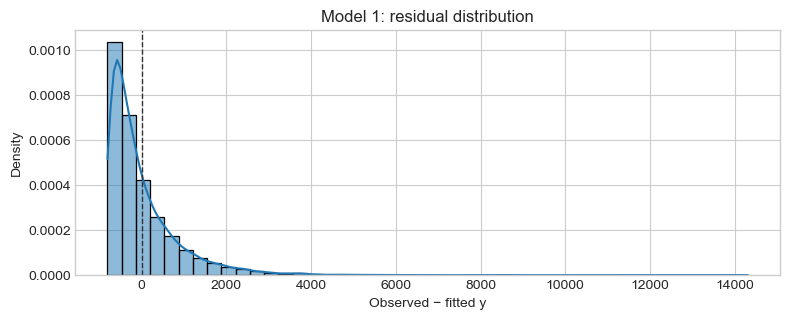

In [26]:
fig, ax = plt.subplots(figsize=(8.0,3.3))
sns.histplot(residual_data['Model 1'],stat='density',bins=45,kde=True,color='#1f77b4',ax=ax)
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set(title='Model 1: residual distribution',xlabel='Observed − fitted y',ylabel='Density')
plt.tight_layout();plt.show()

#### 2.5.1 Model 1: normal Q–Q plot

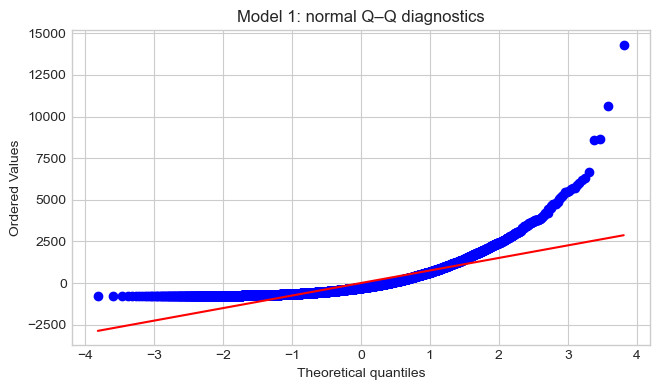

In [27]:
fig, ax = plt.subplots(figsize=(6.7,4.0))
stats.probplot(residual_data['Model 1'],dist='norm',plot=ax)
ax.set(title='Model 1: normal Q–Q diagnostics')
plt.tight_layout();plt.show()

#### 2.5.2 Model 2: residual histogram

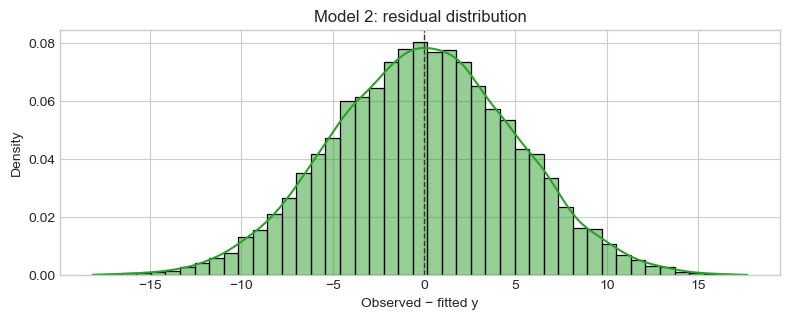

In [28]:
fig, ax = plt.subplots(figsize=(8.0,3.3))
sns.histplot(residual_data['Model 2'],stat='density',bins=45,kde=True,color='#2ca02c',ax=ax)
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set(title='Model 2: residual distribution',xlabel='Observed − fitted y',ylabel='Density')
plt.tight_layout();plt.show()

#### 2.5.2 Model 2: normal Q–Q plot

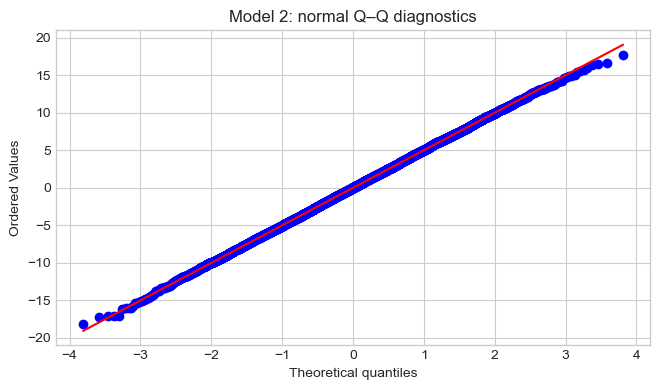

In [29]:
fig, ax = plt.subplots(figsize=(6.7,4.0))
stats.probplot(residual_data['Model 2'],dist='norm',plot=ax)
ax.set(title='Model 2: normal Q–Q diagnostics')
plt.tight_layout();plt.show()

#### 2.5.3 Model 3: residual histogram

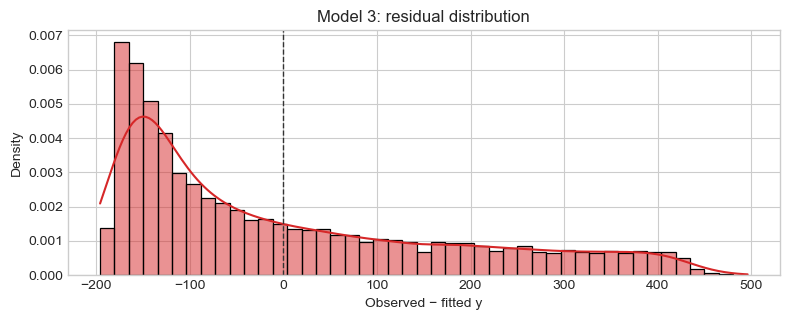

In [30]:
fig, ax = plt.subplots(figsize=(8.0,3.3))
sns.histplot(residual_data['Model 3'],stat='density',bins=45,kde=True,color='#d62728',ax=ax)
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set(title='Model 3: residual distribution',xlabel='Observed − fitted y',ylabel='Density')
plt.tight_layout();plt.show()

#### 2.5.3 Model 3: normal Q–Q plot

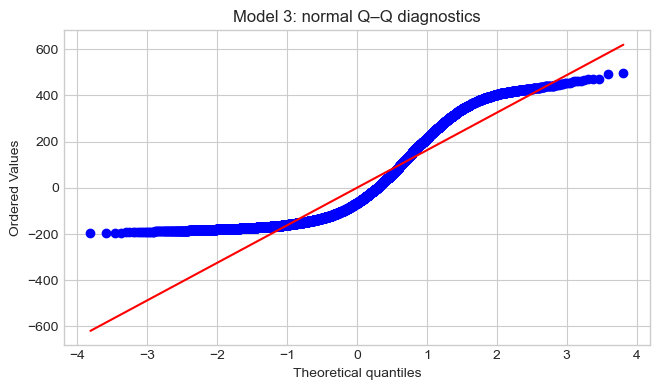

In [31]:
fig, ax = plt.subplots(figsize=(6.7,4.0))
stats.probplot(residual_data['Model 3'],dist='norm',plot=ax)
ax.set(title='Model 3: normal Q–Q diagnostics')
plt.tight_layout();plt.show()

#### 2.5.4 Model 4: residual histogram

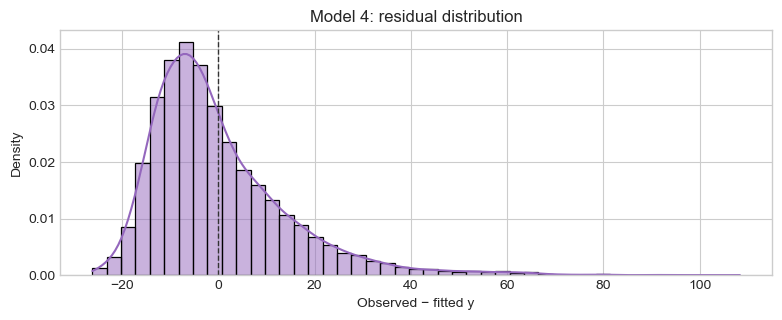

In [32]:
fig, ax = plt.subplots(figsize=(8.0,3.3))
sns.histplot(residual_data['Model 4'],stat='density',bins=45,kde=True,color='#9467bd',ax=ax)
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set(title='Model 4: residual distribution',xlabel='Observed − fitted y',ylabel='Density')
plt.tight_layout();plt.show()

#### 2.5.4 Model 4: normal Q–Q plot

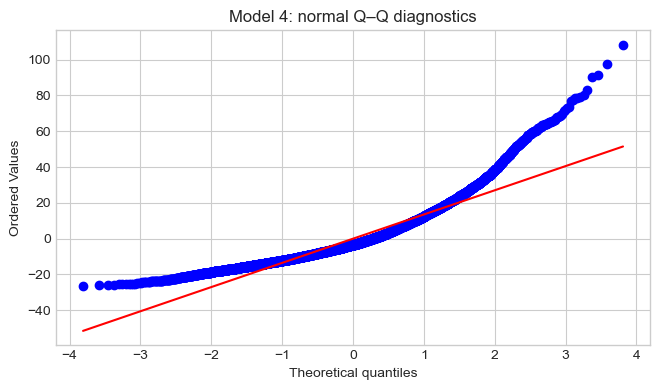

In [33]:
fig, ax = plt.subplots(figsize=(6.7,4.0))
stats.probplot(residual_data['Model 4'],dist='norm',plot=ax)
ax.set(title='Model 4: normal Q–Q diagnostics')
plt.tight_layout();plt.show()

#### 2.5.5 Model 5: residual histogram

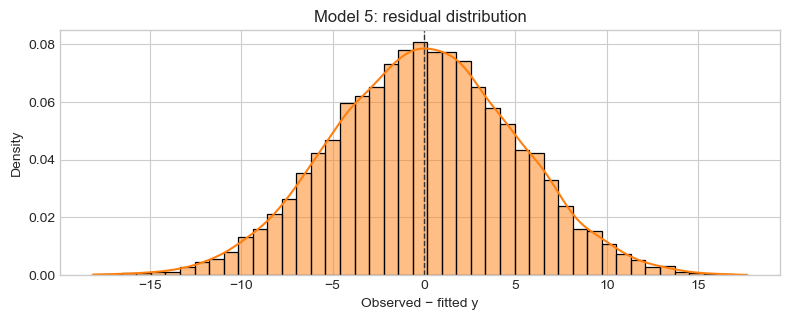

In [34]:
fig, ax = plt.subplots(figsize=(8.0,3.3))
sns.histplot(residual_data['Model 5'],stat='density',bins=45,kde=True,color='#ff7f0e',ax=ax)
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set(title='Model 5: residual distribution',xlabel='Observed − fitted y',ylabel='Density')
plt.tight_layout();plt.show()

#### 2.5.5 Model 5: normal Q–Q plot

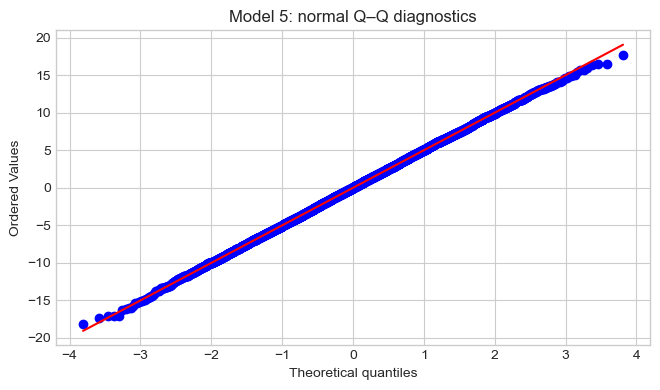

In [35]:
fig, ax = plt.subplots(figsize=(6.7,4.0))
stats.probplot(residual_data['Model 5'],dist='norm',plot=ax)
ax.set(title='Model 5: normal Q–Q diagnostics')
plt.tight_layout();plt.show()

### 2.6 Model selection — AIC, BIC and residual evidence

In [36]:
# Compute the selection from the comparison results, rather than assuming Model 2 or Model 5.
best_aic_name = evaluation_df.loc[evaluation_df['AIC'].idxmin(), 'Candidate']
best_bic_name = evaluation_df.loc[evaluation_df['BIC'].idxmin(), 'Candidate']
print('AIC selects:', best_aic_name, '| BIC selects:', best_bic_name)
if best_aic_name != best_bic_name:
    print('AIC/BIC disagree; use BIC as a cautious default and discuss residual diagnostics.')
selected_name = best_aic_name if best_aic_name == best_bic_name else best_bic_name
print('Selected best-supported candidate:', selected_name)
print('Gaussian residual JB p-value:', float(evaluation_df.set_index('Candidate').loc[selected_name, 'JB p-value']))
selected_assets = trained_models[selected_name]
print('Selected original-scale equation:')
print(f"y_hat = {selected_assets['raw_intercept']:.6f} + " +
      ' + '.join(f"({v:.6f})*{feature}" for feature, v in
                 zip(selected_assets['features'], selected_assets['raw_coef'])))

AIC selects: Model 2 | BIC selects: Model 2
Selected best-supported candidate: Model 2
Gaussian residual JB p-value: 0.2836314232195353
Selected original-scale equation:
y_hat = 120.022108 + (4.480472)*x4 + (1.200184)*x1_cube + (0.800003)*x3_quad


#### 2.6.1 Optional nested-model F test

In [37]:
# A specific check of the suggested Model 5 versus nested Model 2.

# This is supplementary to the assignment's requested AIC, BIC and residual comparison.
if set(candidate_models['Model 2'].columns).issubset(candidate_models['Model 5'].columns):
    rss2 = evaluation_df.set_index('Candidate').loc['Model 2', 'RSS']
    rss5 = evaluation_df.set_index('Candidate').loc['Model 5', 'RSS']
    added = candidate_models['Model 5'].shape[1] - candidate_models['Model 2'].shape[1]
    denominator_df = n_obs - candidate_models['Model 5'].shape[1] - 1
    f_stat = ((rss2-rss5)/added)/(rss5/denominator_df)
    f_p_value = stats.f.sf(f_stat, added, denominator_df)
    print(f'Nested Model 5 vs Model 2: F={f_stat:.6f}, p={f_p_value:.6f}')
    print('Model 5 - Model 2: AIC =',round(float(evaluation_df.set_index('Candidate').loc['Model 5','AIC']-evaluation_df.set_index('Candidate').loc['Model 2','AIC']),3),
          '; BIC =',round(float(evaluation_df.set_index('Candidate').loc['Model 5','BIC']-evaluation_df.set_index('Candidate').loc['Model 2','BIC']),3))

Nested Model 5 vs Model 2: F=0.327979, p=0.566864
Model 5 - Model 2: AIC = 1.672 ; BIC = 8.882


### 2.7 Holdout evaluation and 95% individual prediction intervals
#### 2.7.1 Train/test split and training-only coefficient estimation

In [38]:
X_best = candidate_models[selected_name]
y_full = data_df['y'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X_best,y_full,test_size=.30,random_state=42)
scaler_best=StandardScaler()
X_train_scaled=scaler_best.fit_transform(X_train)
X_test_scaled=scaler_best.transform(X_test)
selected_ols=LinearRegression().fit(X_train_scaled,y_train)
y_test_pred=selected_ols.predict(X_test_scaled)
test_rmse=np.sqrt(mean_squared_error(y_test,y_test_pred))
test_mae=mean_absolute_error(y_test,y_test_pred)
test_r2=r2_score(y_test,y_test_pred)

print(f'Training n={len(y_train)}, testing n={len(y_test)}')
print(f'Test RMSE={test_rmse:.4f}; MAE={test_mae:.4f}; R²={test_r2:.8f}')


raw_coef_train = selected_ols.coef_ / scaler_best.scale_
raw_intercept_train = selected_ols.intercept_ - float(np.dot(raw_coef_train, scaler_best.mean_))
print('Training-only original-scale intercept:', f'{raw_intercept_train:.6f}')
display(pd.DataFrame({'Feature':list(X_best.columns),'Raw-scale training coefficient':raw_coef_train}))

Training n=7000, testing n=3000
Test RMSE=5.0831; MAE=4.0531; R²=0.99996638
Training-only original-scale intercept: 120.096291


,Feature,Raw-scale training coefficient
0,x4,4.488462
1,x1_cube,1.199899
2,x3_quad,0.800005


#### 2.7.2 Held-out model accuracy

In [39]:
display(pd.DataFrame({'Measure':['Test RMSE','Test MAE','Test R²'], 'Value':[test_rmse,test_mae,test_r2]}).round(8))

,Measure,Value
0,Test RMSE,5.083064
1,Test MAE,4.053147
2,Test R²,0.999966


#### 2.7.3 Compute confidence and prediction intervals

In [40]:
n_train=len(y_train); p_num=X_train_scaled.shape[1]
resid_train=y_train-selected_ols.predict(X_train_scaled)
s_err=np.sqrt(np.sum(resid_train**2)/(n_train-p_num-1))
X_tr_design=np.column_stack([np.ones(n_train),X_train_scaled])
X_te_design=np.column_stack([np.ones(len(y_test)),X_test_scaled])
cov_mat=np.linalg.inv(X_tr_design.T@X_tr_design)
mean_se=s_err*np.sqrt(np.einsum('ij,jk,ik->i',X_te_design,cov_mat,X_te_design))
se_pred=np.sqrt(s_err**2+mean_se**2)
t_critical=stats.t.ppf(.975,df=n_train-p_num-1)
pi_lower=y_test_pred-t_critical*se_pred
pi_upper=y_test_pred+t_critical*se_pred
ci_mean_lower=y_test_pred-t_critical*mean_se
ci_mean_upper=y_test_pred+t_critical*mean_se
coverage=np.mean((y_test>=pi_lower)&(y_test<=pi_upper))

print(f'95% prediction interval empirical coverage={coverage:.2%}')
print(f'Mean prediction interval width={np.mean(pi_upper-pi_lower):.4f}')


print('Prediction interval coverage:', f'{coverage:.2%}')
print('Mean prediction interval width:',f'{np.mean(pi_upper-pi_lower):.4f}')

95% prediction interval empirical coverage=94.63%
Mean prediction interval width=19.5219
Prediction interval coverage: 94.63%
Mean prediction interval width: 19.5219


#### 2.7.4 Plot predicted and observed power with individual 95% error bars

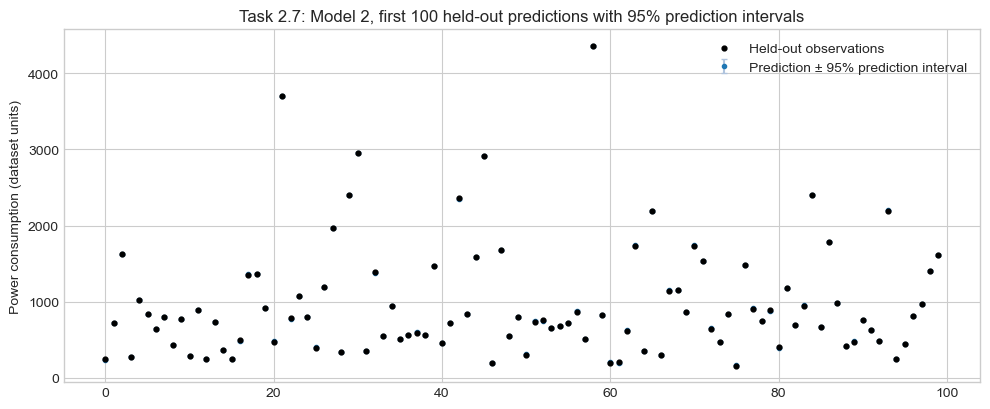

In [41]:
# Two aligned views make the 95% error bars interpretable even when the full
# simulated power signal spans thousands of units.
indices=np.arange(100)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.errorbar(indices, y_test_pred[indices], yerr=t_critical*se_pred[indices],
                 fmt='o', markersize=3, capsize=2, color='tab:blue', ecolor='lightsteelblue',
                 label='Prediction ± 95% prediction interval')
ax.scatter(indices, y_test[indices], s=12, color='black', zorder=3,
                label='Held-out observations')
ax.set_ylabel('Power consumption (dataset units)')
ax.set_title(f'Task 2.7: {selected_name}, first 100 held-out predictions with 95% prediction intervals')
ax.legend()


plt.tight_layout();plt.show()

#### 2.7.5 Plot the prediction intervals on a residual scale

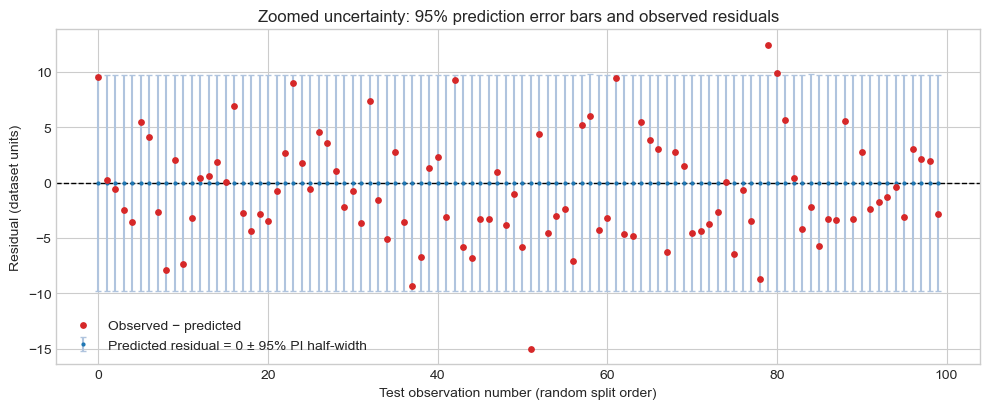

In [42]:
fig, ax = plt.subplots(figsize=(10,4.2))
# A residual-scale view of the same observations reveals the interval width.
ax.errorbar(indices, np.zeros(len(indices)), yerr=t_critical*se_pred[indices],
                 fmt='o', markersize=2, capsize=2, color='tab:blue', ecolor='lightsteelblue',
                 label='Predicted residual = 0 ± 95% PI half-width')
ax.scatter(indices, y_test[indices]-y_test_pred[indices], color='#d62728',
                s=15, zorder=3, label='Observed − predicted')
ax.axhline(0, linestyle='--', color='black', linewidth=1)
ax.set_xlabel('Test observation number (random split order)')
ax.set_ylabel('Residual (dataset units)')
ax.set_title('Zoomed uncertainty: 95% prediction error bars and observed residuals')
ax.legend()
plt.tight_layout();plt.show()

### 2.8 Supplementary robustness checks

In [43]:
# An untransformed linear benchmark (not one of the five candidates).

linear_baseline = LinearRegression().fit(data_df[['x1','x2','x3','x4']], y_full)
linear_baseline_pred = linear_baseline.predict(data_df[['x1','x2','x3','x4']])
print('Ordinary linear baseline full-data RMSE:',
      f'{np.sqrt(mean_squared_error(y_full, linear_baseline_pred)):.5f}')
print('Ordinary linear baseline full-data R²:',
      f'{r2_score(y_full, linear_baseline_pred):.6f}')

Ordinary linear baseline full-data RMSE: 434.01413
Ordinary linear baseline full-data R²: 0.758661


#### 2.8.1 Chronological train/test split

In [44]:
# Time-ordered 70:30 split of the selected polynomial features.

cutoff = int(0.7 * len(X_best))
chrono_scaler = StandardScaler()
Z_chrono_train = chrono_scaler.fit_transform(X_best.iloc[:cutoff])
Z_chrono_test = chrono_scaler.transform(X_best.iloc[cutoff:])
chrono_model = LinearRegression().fit(Z_chrono_train, y_full[:cutoff])
chrono_pred = chrono_model.predict(Z_chrono_test)

print('Chronological holdout RMSE:',
      f'{np.sqrt(mean_squared_error(y_full[cutoff:], chrono_pred)):.5f}')

print('Chronological holdout R²:',
      f'{r2_score(y_full[cutoff:], chrono_pred):.8f}')

Chronological holdout RMSE: 5.08700
Chronological holdout R²: 0.99996314


## Task 3 — Rejection Approximate Bayesian Computation (ABC)
### 3.1 Parameter selection from the original-scale Task 2.1 estimates

In [45]:
# Select the two largest ABSOLUTE original-scale least-squares parameters.

selected_full = trained_models[selected_name]
full_features = candidate_models[selected_name]
full_resid = residual_data[selected_name]
parameter_names = ['Intercept'] + list(full_features.columns)
raw_parameters = np.r_[selected_full['raw_intercept'], selected_full['raw_coef']]
selected_positions = np.argsort(np.abs(raw_parameters))[::-1][:2]
other_positions = [i for i in range(len(parameter_names)) if i not in selected_positions]
selected_feature_names = [parameter_names[i] for i in selected_positions]
ols_top2 = raw_parameters[selected_positions]

print('Largest two absolute Task 2.1 parameters:', selected_feature_names)
print('Their original-equation estimates:', ols_top2)
print('Other parameters fixed at:', {parameter_names[i]: float(raw_parameters[i]) for i in other_positions})

Largest two absolute Task 2.1 parameters: ['Intercept', 'x4']
Their original-equation estimates: [120.02210818   4.48047191]
Other parameters fixed at: {'x1_cube': 1.200184400699344, 'x3_quad': 0.8000025660116106}


### 3.2 Gaussian synthetic least-squares summaries

In [46]:
# The raw design matrix describes precisely the selected candidate polynomial equation.
D = np.column_stack([np.ones(n_obs), full_features.to_numpy(dtype=float)])
Z_two = D[:, selected_positions]
fixed_signal = D[:, other_positions] @ raw_parameters[other_positions]
observed_adjusted = y_full - fixed_signal
# Observed two-dimensional summary, conditional on the remaining fixed slopes.
Q = np.linalg.pinv(Z_two)
observed_summary = Q @ observed_adjusted
unbiased_variance = float(np.sum(full_resid**2)/(n_obs - D.shape[1]))
summary_covariance = unbiased_variance * np.linalg.pinv(Z_two.T @ Z_two)
se_two = np.sqrt(np.diag(summary_covariance))

### 3.3 Prior ranges — two uniform priors

In [47]:
# A transparent data-informed UNIFORM prior around each Task 2.1 point estimate.
prior_half_width = np.maximum(12*se_two, 0.03*np.abs(ols_top2))
prior_lower = ols_top2-prior_half_width
prior_upper = ols_top2+prior_half_width
for name, lo, hi in zip(selected_feature_names, prior_lower, prior_upper):
    print(f'{name}: prior Uniform({lo:.6f}, {hi:.6f})')

Intercept: prior Uniform(116.421445, 123.622771)
x4: prior Uniform(4.280073, 4.680871)


### 3.4 Rejection sampling using Mahalanobis distance

In [48]:
n_simulations = 600_000
rng = np.random.default_rng(42)
prior_samples = rng.uniform(prior_lower, prior_upper, size=(n_simulations, 2))

# Each draw has the Gaussian sampling distribution of the OLS summary from
# a synthetic dataset with independent N(0, estimated variance) errors.

simulated_summary = prior_samples + rng.multivariate_normal(
    mean=np.zeros(2), cov=summary_covariance, size=n_simulations)
summary_distance = simulated_summary - observed_summary
inverse_covariance = np.linalg.pinv(summary_covariance)
mahalanobis_sq = np.einsum('ij,jk,ik->i', summary_distance, inverse_covariance, summary_distance)
abc_epsilon = 1.5
accepted = prior_samples[mahalanobis_sq <= abc_epsilon**2]
if len(accepted) < 500:
    raise RuntimeError('Too few ABC acceptances; increase simulation count or document a larger tolerance.')
print(f'ABC proposals: {n_simulations:,}; accepted {len(accepted):,}; '
      f'acceptance rate {len(accepted)/n_simulations:.2%}; tolerance {abc_epsilon:.2f}')

ABC proposals: 600,000; accepted 1,291; acceptance rate 0.22%; tolerance 1.50


### 3.5 Posterior numerical summaries

In [49]:
for i, label in enumerate(selected_feature_names):
    lo, median, hi = np.quantile(accepted[:,i],[.025,.5,.975])
    print(f'{label}: OLS={ols_top2[i]:.5f}; ABC mean={accepted[:,i].mean():.5f}; '
          f'posterior median={median:.5f}; 95% credible interval [{lo:.5f}, {hi:.5f}]')
print('Joint accepted-parameter correlation:',f'{np.corrcoef(accepted.T)[0,1]:.4f}')

Intercept: OLS=120.02211; ABC mean=120.02806; posterior median=120.02942; 95% credible interval [119.84623, 120.20263]
x4: OLS=4.48047; ABC mean=4.47950; posterior median=4.47970; 95% credible interval [4.43865, 4.52008]
Joint accepted-parameter correlation: -0.7059


### 3.6 Individual marginal posterior for the intercept

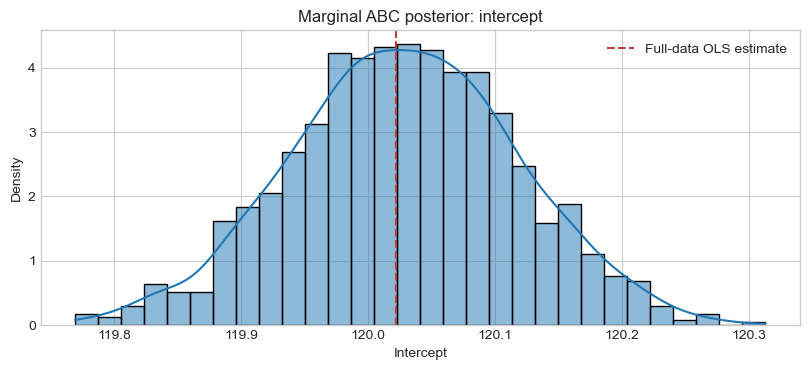

In [50]:
fig, ax = plt.subplots(figsize=(8.2,3.8))
sns.histplot(accepted[:,0],bins=30,kde=True,stat='density',color='#1f77b4',ax=ax)
ax.axvline(ols_top2[0],color='#c13b3b',ls='--',label='Full-data OLS estimate')
ax.set(title='Marginal ABC posterior: intercept',xlabel='Intercept',ylabel='Density')
ax.legend();plt.tight_layout();plt.show()

### 3.7 Individual marginal posterior for the x4 coefficient

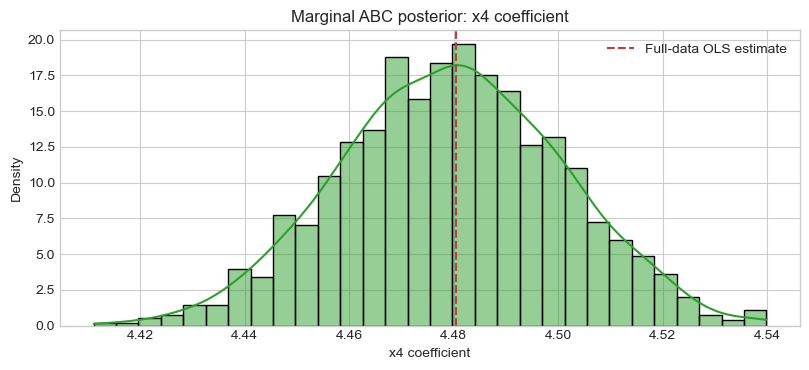

In [51]:
fig, ax = plt.subplots(figsize=(8.2,3.8))
sns.histplot(accepted[:,1],bins=30,kde=True,stat='density',color='#2ca02c',ax=ax)
ax.axvline(ols_top2[1],color='#c13b3b',ls='--',label='Full-data OLS estimate')
ax.set(title='Marginal ABC posterior: x4 coefficient',xlabel='x4 coefficient',ylabel='Density')
ax.legend();plt.tight_layout();plt.show()

### 3.8 Joint posterior — how the two parameters vary together

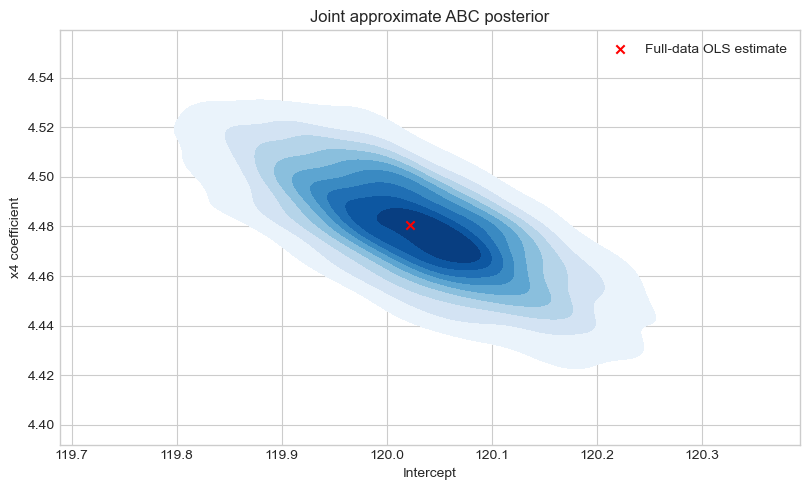

In [52]:
fig, ax = plt.subplots(figsize=(8.2,5.0))
sns.kdeplot(x=accepted[:,0],y=accepted[:,1],fill=True,levels=10,cmap='Blues',ax=ax)
ax.scatter([ols_top2[0]],[ols_top2[1]],color='red',marker='x',label='Full-data OLS estimate')
ax.set(xlabel='Intercept',ylabel='x4 coefficient',title='Joint approximate ABC posterior')
ax.legend();plt.tight_layout();plt.show()